# Cat and Dog Image Classification CNN

This notebook prepares the Kaggle cat/dog dataset, trains a convolutional neural network, and compares actual labels with model predictions.

## 1. Import Dependencies

In [11]:
# Import plotting, operating-system, TensorFlow, and dataset utilities.
import matplotlib.pyplot as plt
import os
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import image_dataset_from_directory

## 2. Prepare the Cat and Dog Dataset

In [12]:
# Set source and output paths.
source_dir = 'data_from_kaggle'
output_dir = 'data'

if not os.path.exists(source_dir):
    print("Please download and extract the provided data_from_kaggle.zip.")
    exit(1)

# Organize images by cat/dog label from their Kaggle filenames.
for split in ('train', 'test'):
    for filename in os.listdir(os.path.join(source_dir, split)):
        class_name = filename.split('.', 1)[0]
        if class_name not in ('cat', 'dog'):
            continue

        destination_dir = os.path.join(output_dir, split, class_name)
        os.makedirs(destination_dir, exist_ok=True)

        source_path = os.path.abspath(os.path.join(source_dir, split, filename))
        link_path = os.path.join(destination_dir, filename)
        if not os.path.lexists(link_path):
            os.symlink(source_path, link_path)

# The training folder is used for model training and validation.
train_dataset = image_dataset_from_directory(
    os.path.join(output_dir, 'train'),
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(128, 128),
    batch_size=32
)

validation_dataset = image_dataset_from_directory(
    os.path.join(output_dir, 'train'),
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(128, 128),
    batch_size=32
)

# The Kaggle test folder provides independent images for predictions.
test_dataset = image_dataset_from_directory(
    os.path.join(output_dir, 'test'),
    image_size=(128, 128),
    batch_size=32,
    shuffle=True,
    seed=123
)

Found 19989 files belonging to 2 classes.
Using 15992 files for training.
Found 19989 files belonging to 2 classes.
Using 3997 files for validation.
Found 5000 files belonging to 2 classes.


## 3. Define the Convolutional Neural Network

In [13]:
# Build the convolutional feature extractor and binary classifier.
inputs = keras.Input(shape=(128, 128, 3))
x = layers.Conv2D(32, (3, 3), activation='relu')(inputs)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(128, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(1, activation='sigmoid')(x)

model = keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train the Convolutional Neural Network

In [14]:
# Train the model for 10 epochs using the validation dataset.
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - accuracy: 0.5388 - loss: 3.4157 - val_accuracy: 0.5497 - val_loss: 0.7118
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.6822 - loss: 0.6213 - val_accuracy: 0.6925 - val_loss: 0.5776
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.7614 - loss: 0.5093 - val_accuracy: 0.7781 - val_loss: 0.4732
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - accuracy: 0.8018 - loss: 0.4425 - val_accuracy: 0.7776 - val_loss: 0.4742
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - accuracy: 0.8372 - loss: 0.3819 - val_accuracy: 0.7963 - val_loss: 0.5115
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.8600 - loss: 0.3372 - val_accuracy: 0.7723 - val_loss: 0.7562
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - accuracy: 0.8875 - loss: 0.2756 - val_accuracy: 0.8074 - val_loss: 0.5161
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - accuracy: 0.9120 - loss: 0.2322 - 

## 5. Cat and Dog Prediction Results

The title shows the actual class, and the label beneath each image shows the model's predicted class and whether it was correct.

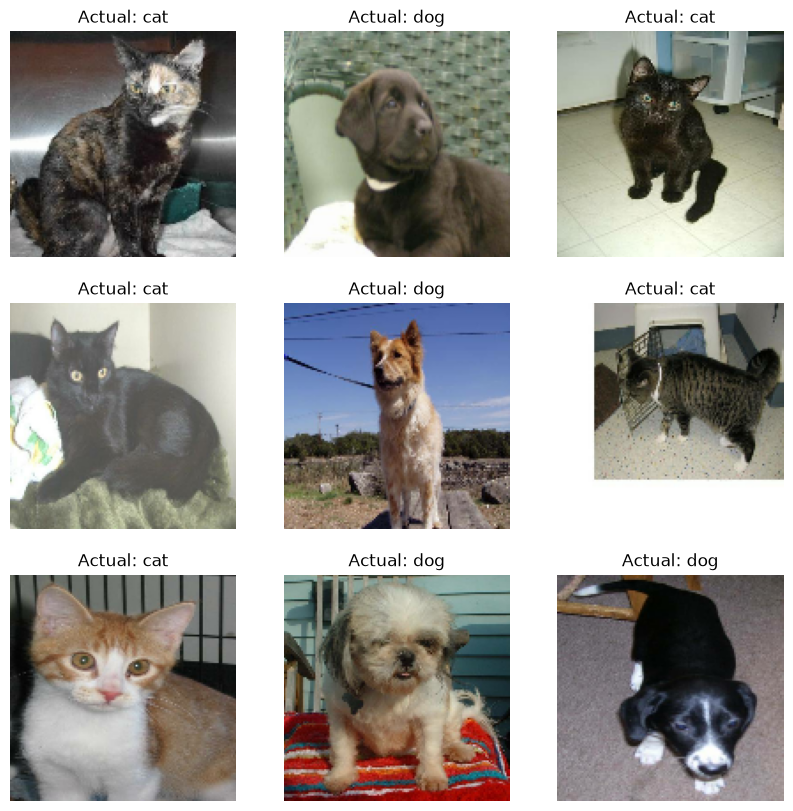

In [17]:
# Display nine test images with their actual and predicted classes.
class_names = train_dataset.class_names

for images, labels in test_dataset.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(9):
        # Arrange each image in a 3-by-3 grid.
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        # The integer label represents the cat or dog class.
        actual_class = class_names[int(labels[i].numpy())]
        # Use the model's sigmoid output to predict the class.
        prediction = model.predict(images[i:i + 1], verbose=0)[0][0]
        predicted_class = class_names[int(prediction >= 0.5)]
        # Compare the predicted class with the actual class.
        result = "Correct" if predicted_class == actual_class else "Incorrect"

        plt.title(f"Actual: {actual_class}")
        plt.xlabel(f"Predicted: {predicted_class}\n{result}")
        plt.axis("off")